# Dark and bias analysis

This notebook imports the reusable functions and displays the histogram results inline.

In [4]:
from pathlib import Path

from dark_bias_avg import average_images, find_fits_files, load_images, save_fits_image
from histogram import (
    load_fits_data,
    plot_bias_histograms,
    plot_dark_by_exposure,
    plot_dark_by_temperature,
)

folder = Path('/mnt/c/Data/Histogram')

## Create an average dark frame

In [5]:
dark_folder = Path('/mnt/c/Data/Dark_bias/2026-10-21-Dark-15C60s')
average_dark_path = dark_folder / 'average_dark_60_15.fits'

input_files = find_fits_files(dark_folder, average_dark_path)
images = load_images(input_files)
average_dark = average_images(images)
save_fits_image(average_dark, average_dark_path)

Loaded: Dark_Dark_60sec_Bin1_15.0C_gain0_2026-10-21_163350_frame0001.fit
Loaded: Dark_Dark_60sec_Bin1_15.0C_gain0_2026-10-21_163451_frame0002.fit
Loaded: Dark_Dark_60sec_Bin1_15.0C_gain0_2026-10-21_163552_frame0003.fit
Loaded: Dark_Dark_60sec_Bin1_15.0C_gain0_2026-10-21_163653_frame0004.fit
Loaded: Dark_Dark_60sec_Bin1_15.0C_gain0_2026-10-21_163754_frame0005.fit
Loaded: Dark_Dark_60sec_Bin1_15.0C_gain0_2026-10-21_163855_frame0006.fit
Loaded: Dark_Dark_60sec_Bin1_15.0C_gain0_2026-10-21_163956_frame0007.fit
Loaded: Dark_Dark_60sec_Bin1_15.0C_gain0_2026-10-21_164056_frame0008.fit
Loaded: Dark_Dark_60sec_Bin1_15.0C_gain0_2026-10-21_164157_frame0009.fit
Loaded: Dark_Dark_60sec_Bin1_15.0C_gain0_2026-10-21_164258_frame0010.fit
Loaded: Dark_Dark_60sec_Bin1_15.0C_gain0_2026-10-21_164359_frame0011.fit
Total images loaded: 11
Average image shape: (3672, 5496)
Saved average image to: /mnt/c/Data/Dark_bias/2026-10-21-Dark-15C60s/average_dark_60_15.fits


## Bias histograms

OSError: [Errno 22] Invalid argument: '/mnt/c/Data/Histogram/histogram_master_bias.png'

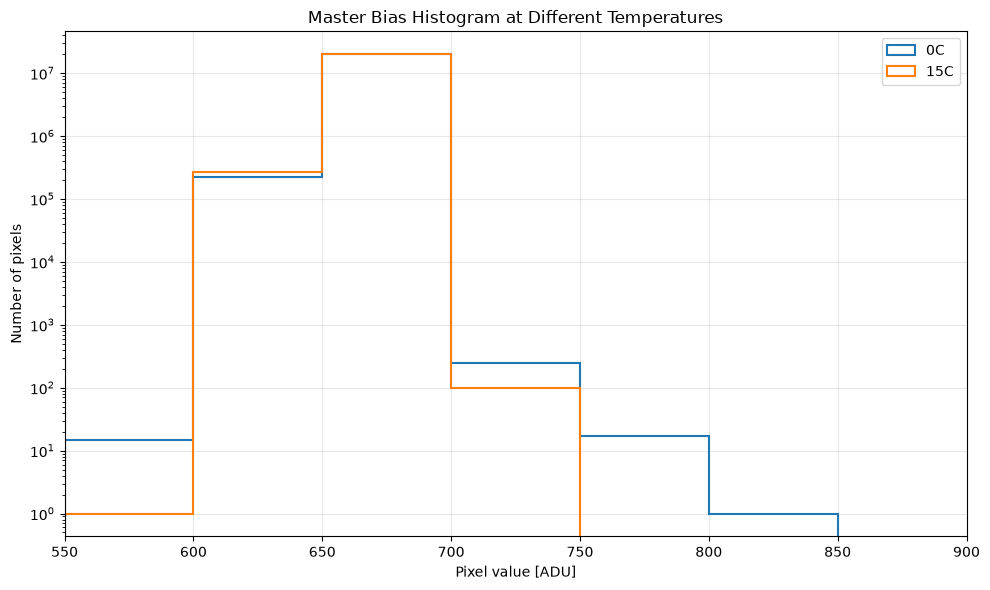

In [6]:
bias_files = {
    '0C': folder / 'master_bias.fits',
    '15C': folder / 'average_bias_15.fits',
}

bias_plot = folder / 'histogram_master_bias.png'
plot_bias_histograms(bias_files, bias_plot)

The bias histogram is displayed above when the cell is run. It is also saved at `bias_plot`.

## Compare temperatures at each exposure time

OSError: [Errno 22] Invalid argument: '/mnt/c/Data/Histogram/histogram_master_dark_by_exposure.png'

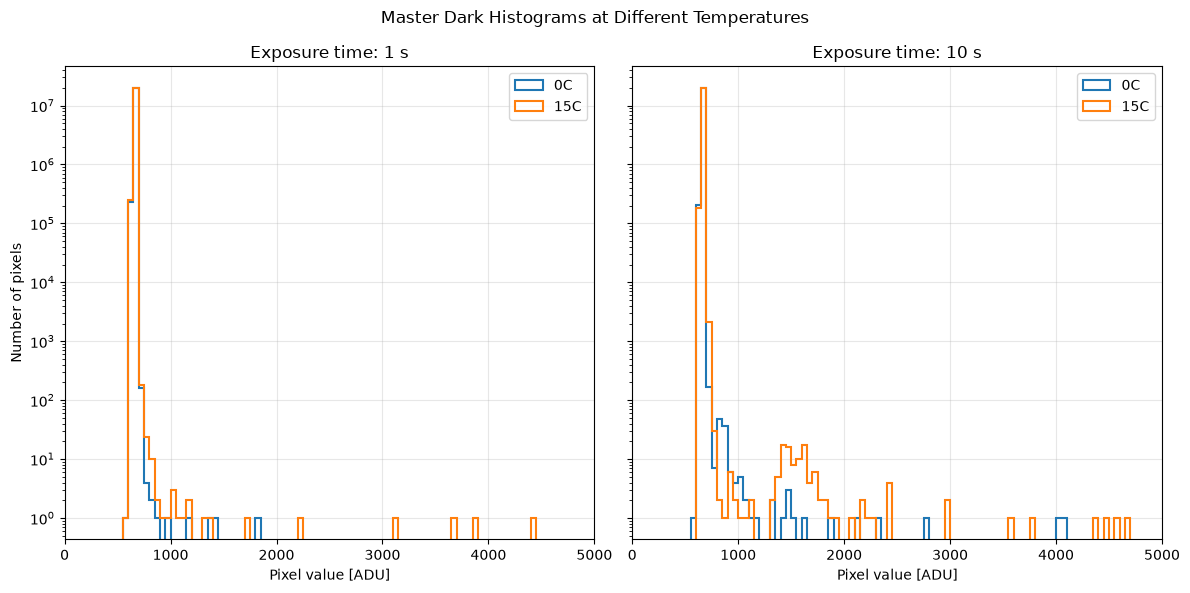

In [7]:
dark_files_by_exposure = {
    '1 s': {
        '0C': folder / 'average_dark_01_0.fits',
        '15C': folder / 'average_dark_01_15.fits',
    },
    '10 s': {
        '0C': folder / 'average_dark_10_0.fits',
        '15C': folder / 'average_dark_10_15.fits',
    },
}

dark_exposure_plot = folder / 'histogram_master_dark_by_exposure.png'
plot_dark_by_exposure(dark_files_by_exposure, dark_exposure_plot)

Each panel above compares the two temperatures for the same exposure time.

## Compare exposure times at each temperature

OSError: [Errno 22] Invalid argument: '/mnt/c/Data/Histogram/histogram_master_dark_by_temperature.png'

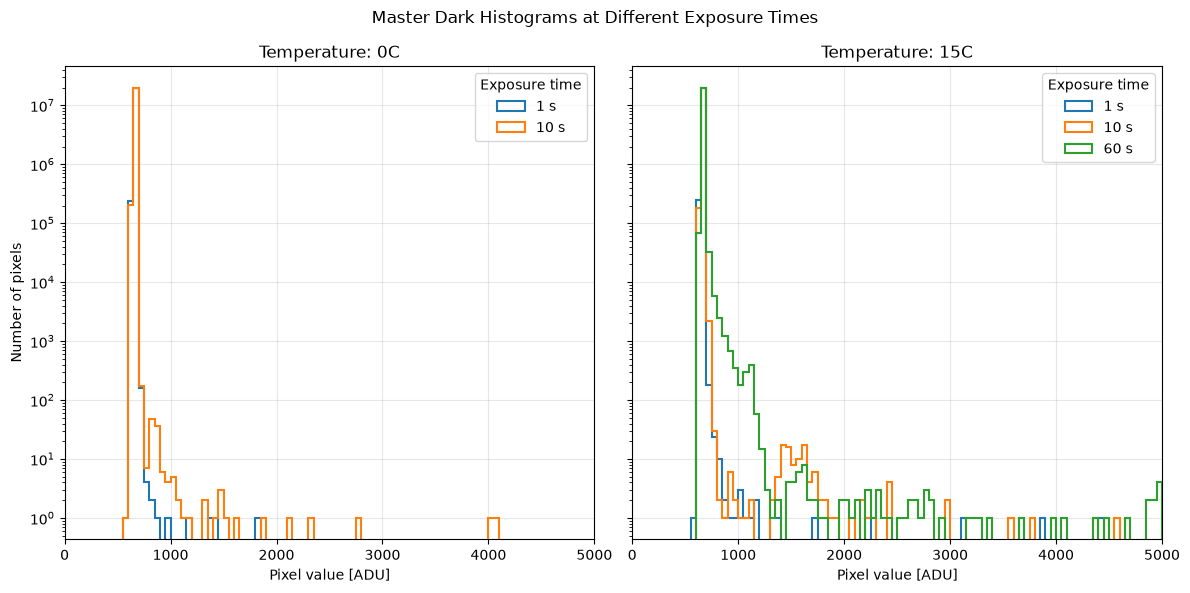

In [8]:
dark_files_by_temperature = {
    '0C': {
        '1 s': folder / 'average_dark_01_0.fits',
        '10 s': folder / 'average_dark_10_0.fits',
    },
    '15C': {
        '1 s': folder / 'average_dark_01_15.fits',
        '10 s': folder / 'average_dark_10_15.fits',
        '60 s': folder / 'average_dark_60_15.fits',
    },
}

dark_temperature_plot = folder / 'histogram_master_dark_by_temperature.png'
plot_dark_by_temperature(dark_files_by_temperature, dark_temperature_plot)

Each panel above compares the exposure times at the same temperature.

## Display saved histogram images again

Run this cell if you want to show the saved PNG files together later in the notebook.

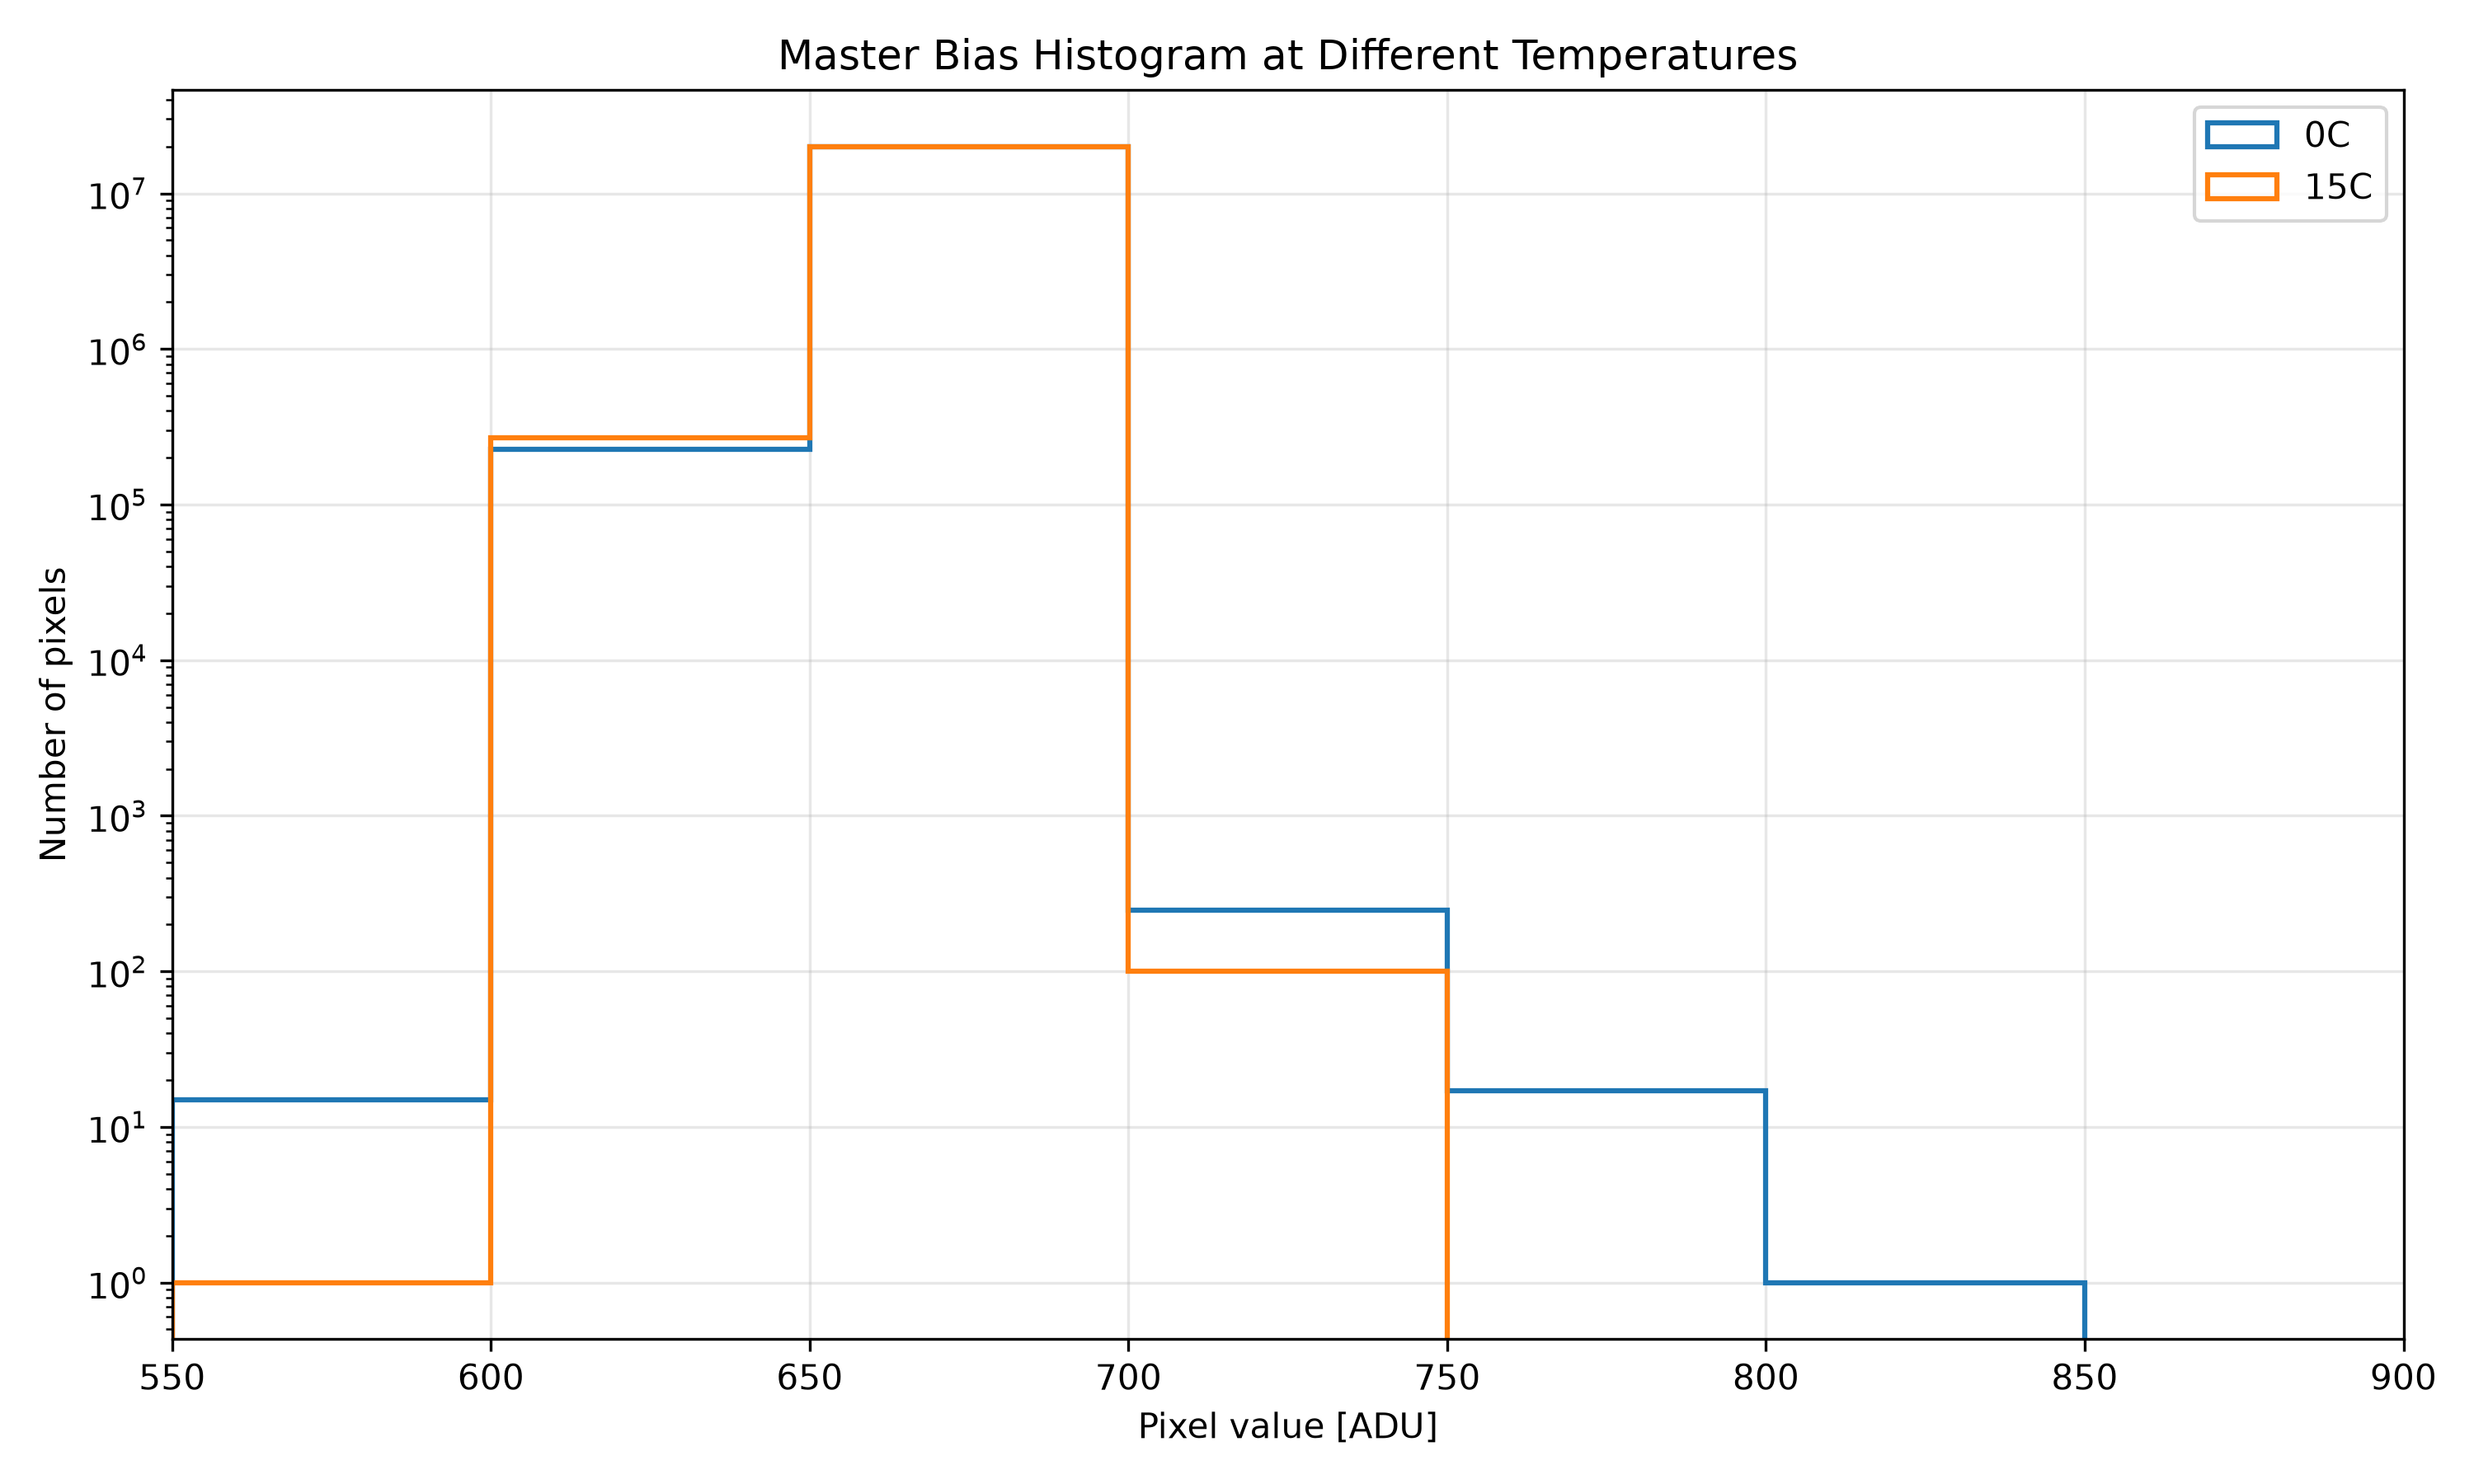

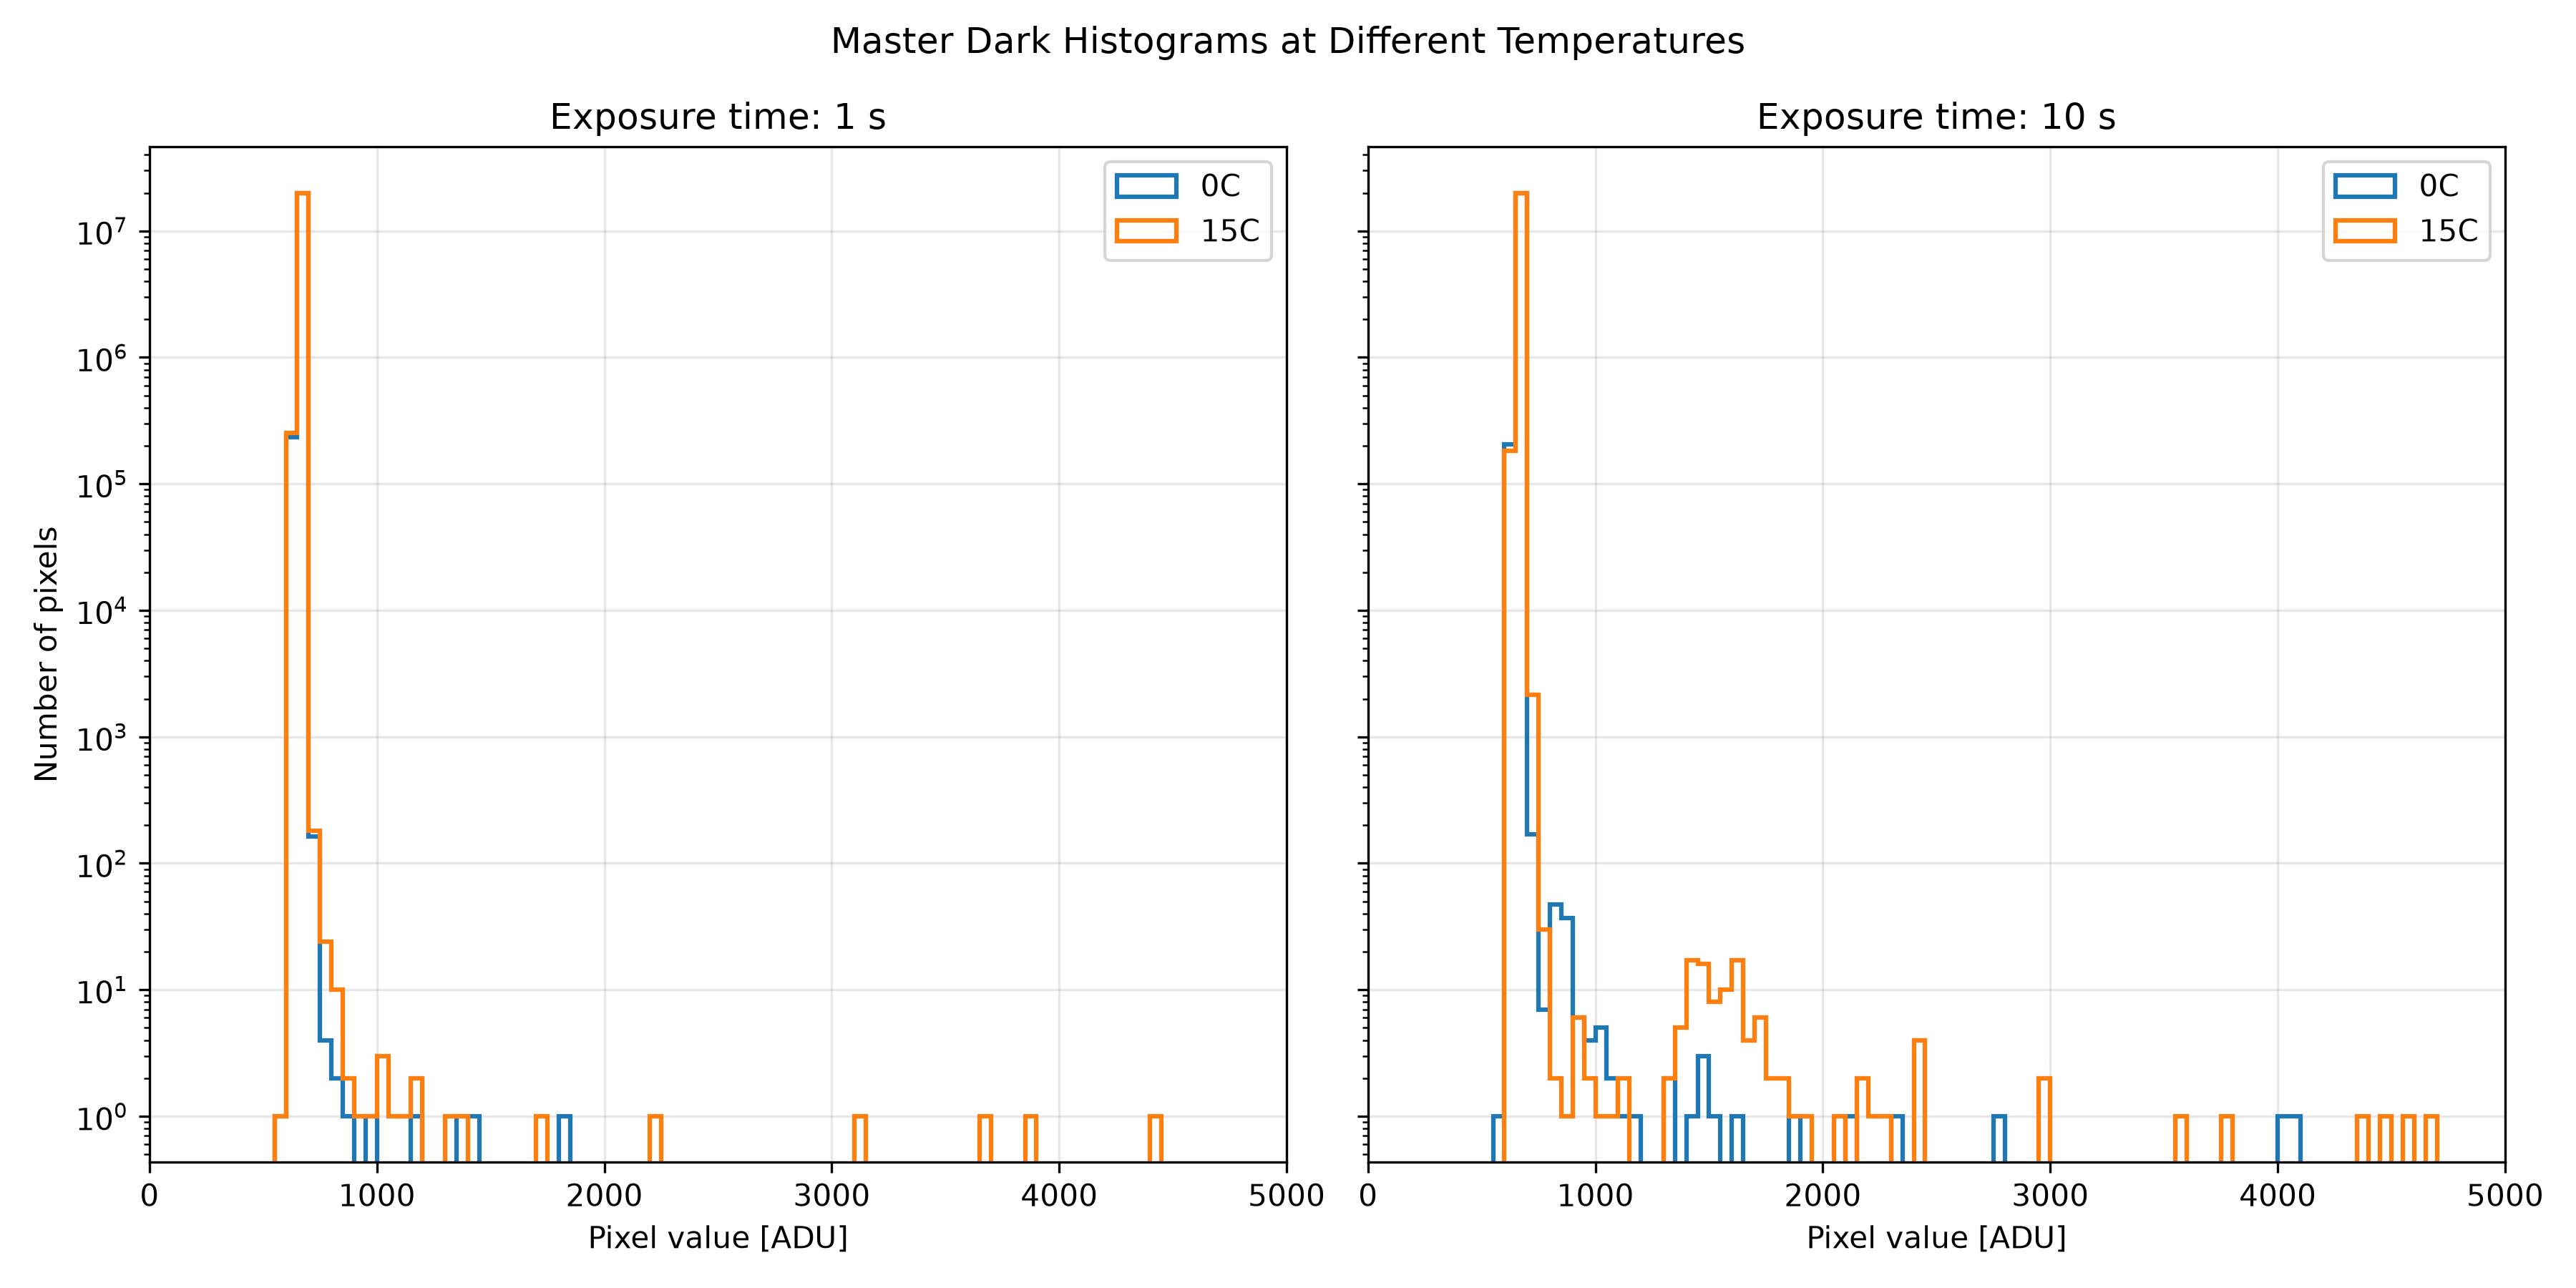

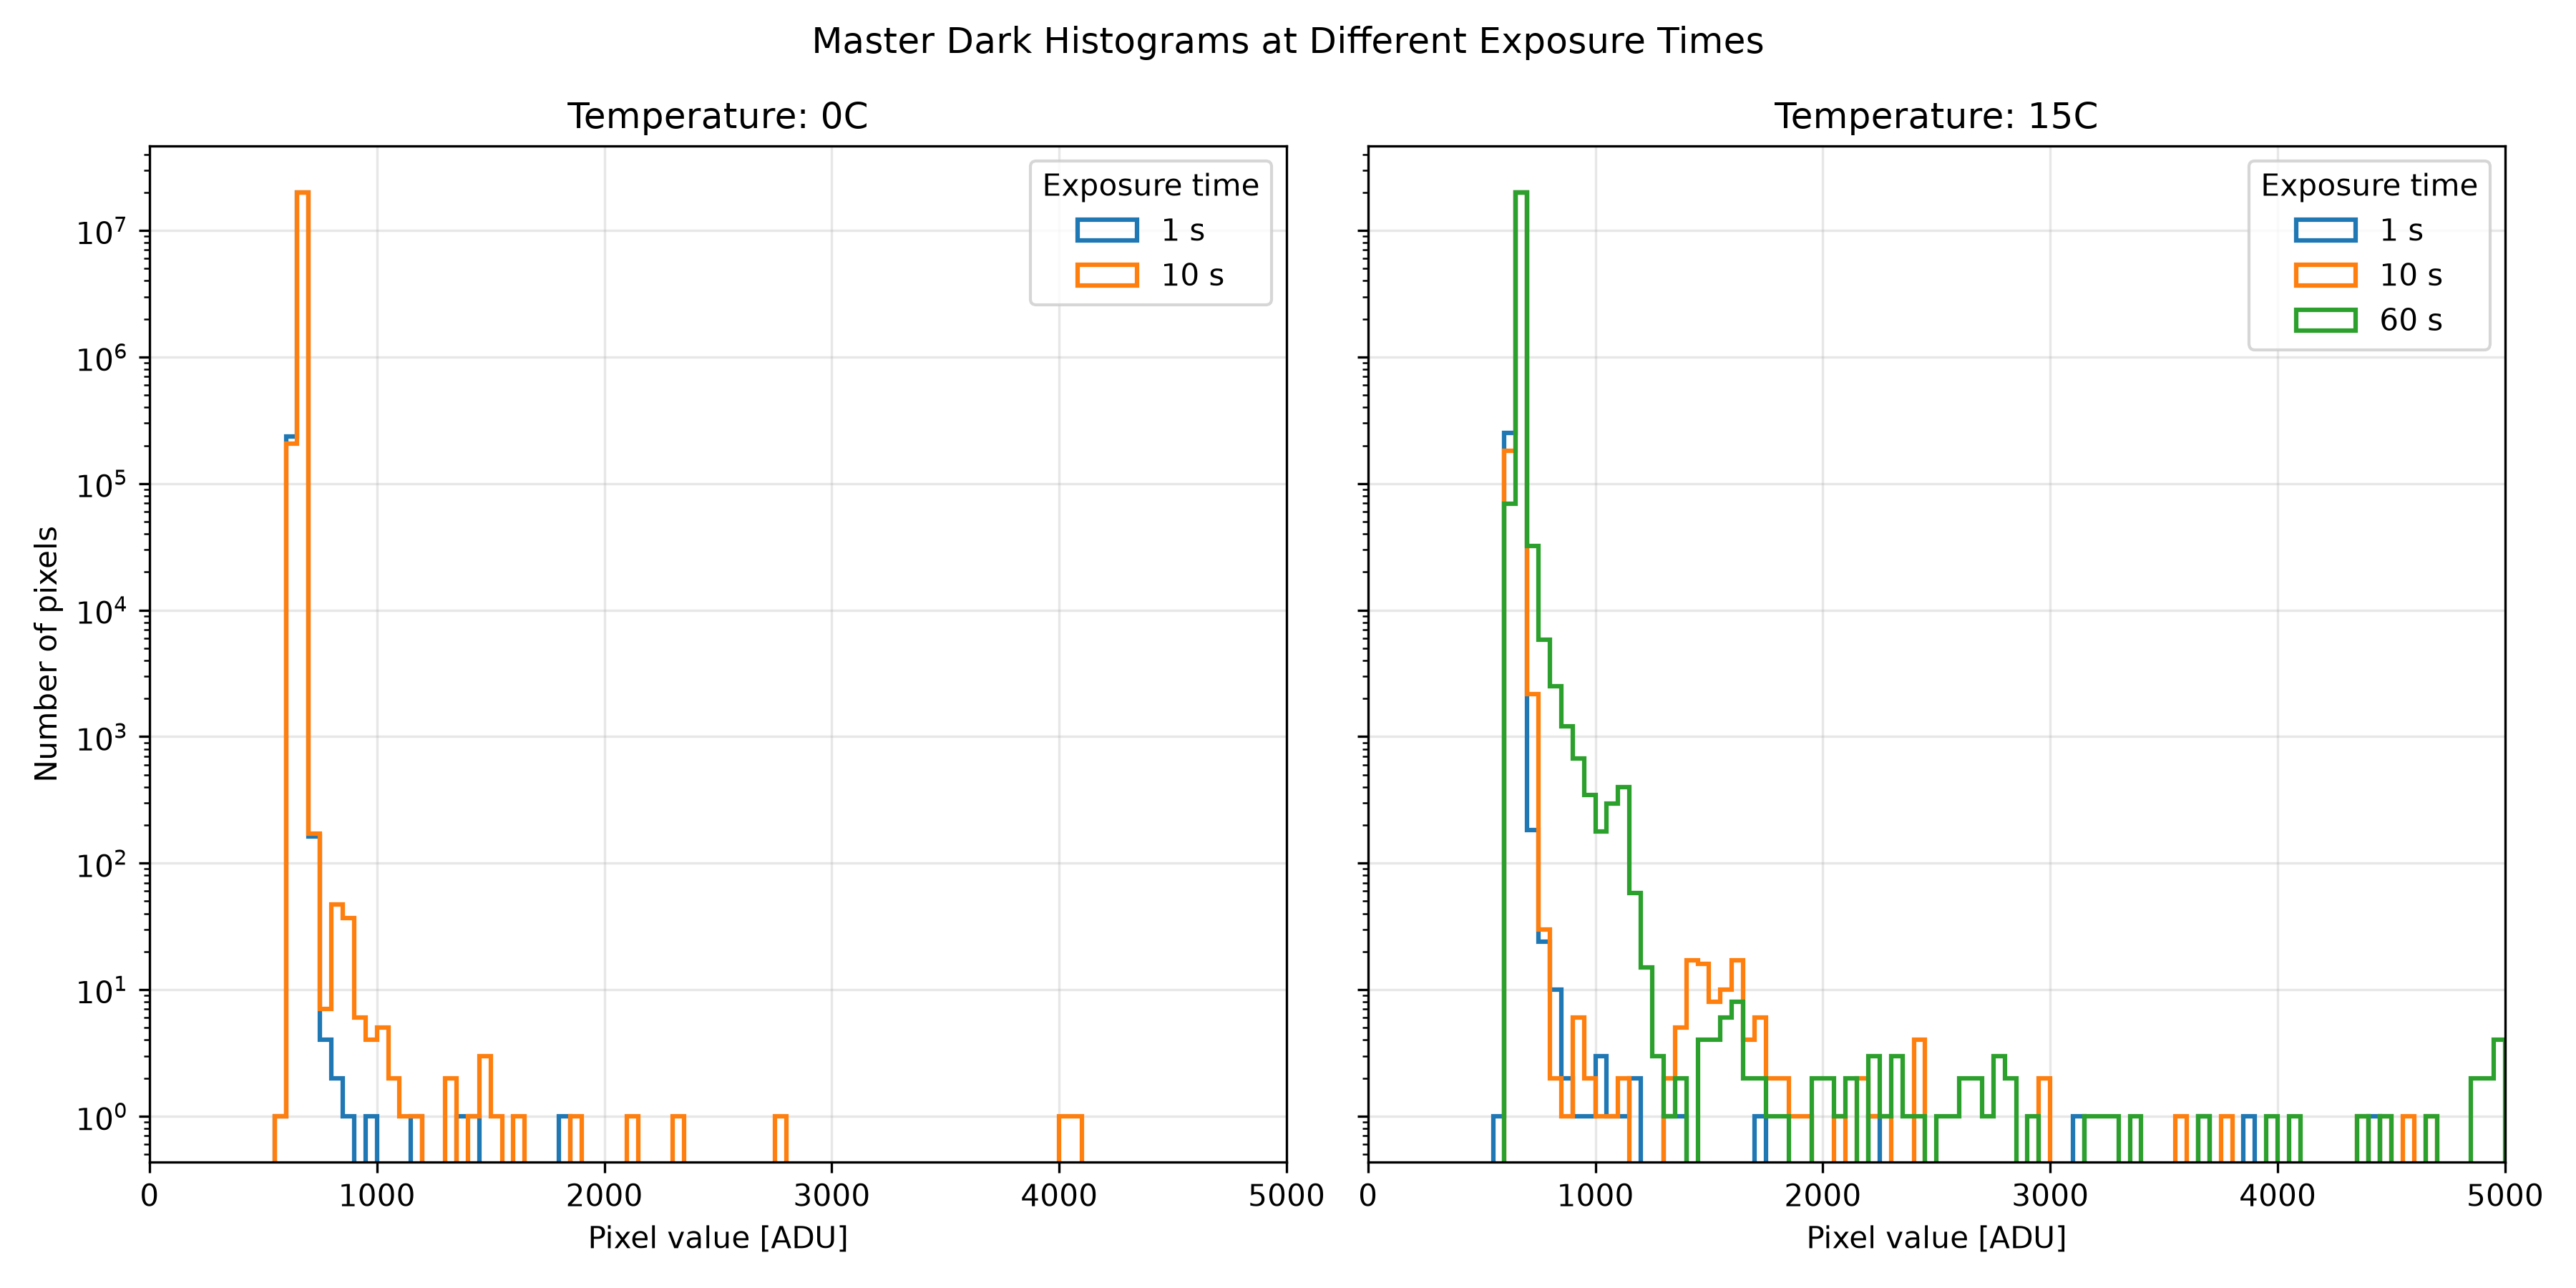

In [9]:
from IPython.display import Image, display

display(Image(filename=str(bias_plot)))
display(Image(filename=str(dark_exposure_plot)))
display(Image(filename=str(dark_temperature_plot)))

## Load pixel values for further analysis

In [10]:
pixel_values = load_fits_data(folder / 'average_dark_10_15.fits')
pixel_values.shape, pixel_values.mean(), pixel_values.std()

((20181312,), np.float64(659.2921350387754), np.float64(11.620934069965775))